In [1]:
import numpy as np
import matplotlib.pyplot as plt
import keras
from keras import layers

In [17]:
def load_data():
    (x_train_full, y_train_full), (x_test, y_test) = keras.datasets.fashion_mnist.load_data()
    
    return x_train_full, y_train_full , x_test, y_test

In [18]:
x_train_full, y_train_full, x_test, y_test = load_data()

In [19]:
def  normalize_data(x_train_full, x_test):
    MAX_INTENSITY = 255.0
    x_train_full = x_train_full.astype("float32") / MAX_INTENSITY
    x_test = x_test.astype("float32") / MAX_INTENSITY

    return x_train_full, x_test

In [20]:
x_train_full, x_test = normalize_data(x_train_full, x_test)

In [21]:
print(x_train_full.min())
print(x_train_full.max())

print(x_test.min())
print(x_test.max())

0.0
1.0
0.0
1.0


In [22]:
def split_data(x_train_full, y_train_full):
    N_TRAIN = 50_000
    x_val, y_val = x_train_full[N_TRAIN:], y_train_full[N_TRAIN:]
    x_train, y_train = x_train_full[:N_TRAIN], y_train_full[:N_TRAIN]
    
    return x_train, y_train, x_val, y_val

In [23]:
x_train, y_train, x_val, y_val = split_data(x_train_full, y_train_full)


In [24]:
CLASS_NAMES = ["T-shirt", "Trouser", "Pullover", 
               "Dress", "Coat", "Sandal", "Shirt", 
               "Sneaker", "Bag", "Ankle boot"]

In [25]:
print(f"train: {x_train.shape}, val: {x_val.shape}, test: {x_test.shape}, class: {len(CLASS_NAMES)}")

train: (50000, 28, 28), val: (10000, 28, 28), test: (10000, 28, 28), class: 10


In [26]:
def show_plot(x_train, y_train):
    fig, axes = plt.subplots(2, 8, figsize=(12, 4))
    for ax, img, label in zip(axes.flat, x_train, y_train):
        ax.imshow(img, cmap="gray")
        ax.set_title(CLASS_NAMES[label], fontsize=9)
        ax.axis("off")

    plt.tight_layout()
    plt.show()

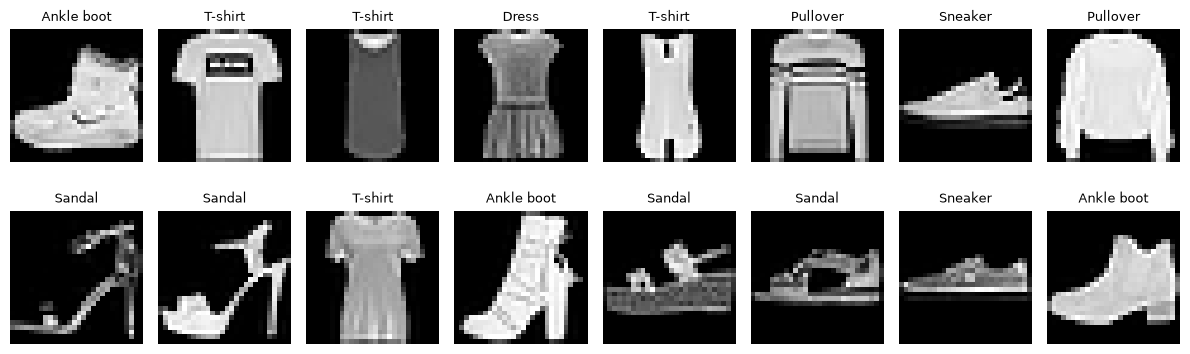

In [27]:
show_plot(x_train, y_train)

In [28]:
import tensorflow as tf

In [29]:
dense_model = keras.Sequential(
    [keras.Input(shape=(28, 28, 1)),
    layers.Flatten(),
    layers.Dense(64, activation="relu"),
    layers.Dropout(0.1),
    layers.Dense(64, activation="relu"),
    layers.Dense(64, activation="relu"),
    layers.Dropout(0.2),
    layers.Dense(64, activation="relu"),
    layers.Dense(64, activation="relu"),
    layers.Dense(10, activation="softmax"),
    ]
)

dense_model.compile(optimizer="adam",
                    loss="sparse_categorical_crossentropy",
                    metrics=["accuracy"])
dense_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_1 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 64)             │        50,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 67,530 (263.79 KB)

 Trainable params: 67,530 (263.79 KB)

 Non-trainable params: 0 (0.00 B)

In [30]:
hist_dense_model = dense_model.fit(x_train, y_train, validation_split=0.2,epochs=20, batch_size=32)

Epoch 1/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.7510 - loss: 0.6740 - val_accuracy: 0.8381 - val_loss: 0.4509
Epoch 2/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.8341 - loss: 0.4606 - val_accuracy: 0.8565 - val_loss: 0.3981
Epoch 3/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.8480 - loss: 0.4189 - val_accuracy: 0.8586 - val_loss: 0.3892
Epoch 4/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.8549 - loss: 0.4018 - val_accuracy: 0.8650 - val_loss: 0.3717
Epoch 5/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.8625 - loss: 0.3802 - val_accuracy: 0.8614 - val_loss: 0.3852
Epoch 6/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.8652 - loss: 0.3658 - val_accuracy: 0.8723 - val_loss: 0.3506
Epoch 7/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.8692 - loss: 0.3563 - val_accuracy: 0.8690 - val_loss: 0.3611
Epoch 8/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.8726 - loss: 0.3491 - 

CNN

In [35]:
cnn_model=keras.Sequential([
    keras.Input(shape=(28, 28, 1)),
    layers.Conv2D(64, 3, activation="relu"),
    layers.MaxPooling2D(),
    layers.Conv2D(64, 3, activation="relu"), 
    layers.Conv2D(64, 3, activation="relu"),
    layers.Conv2D(64, 3, activation="relu"),
    layers.MaxPooling2D(),
    layers.Conv2D(64, 3, activation="relu"),
    layers.Flatten(),
    layers.Dense(10, activation="softmax")
])

cnn_model.compile(optimizer="adam",
                    loss="sparse_categorical_crossentropy",
                    metrics=["accuracy"])

cnn_model.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_15 (Conv2D)              │ (None, 26, 26, 64)     │           640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 13, 13, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_16 (Conv2D)              │ (None, 11, 11, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_17 (Conv2D)              │ (None, 9, 9, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_18 (Conv2D)              │ (None, 7, 7, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_9 (MaxPooling2D)  │ (None, 3, 3, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_19 (Conv2D)              │ (None, 1, 1, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_4 (Flatten)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 149,002 (582.04 KB)

 Trainable params: 149,002 (582.04 KB)

 Non-trainable params: 0 (0.00 B)

In [36]:
# first parametre 3 * 3 + 1 = 10 * 64 = 640
# 3 * 3 * 64 + 1 = 577 * 128 = 73.856
# 3* 3 * 128 + 1 = 1152 * 128 = 147.584



# 28 - 3 + 1 = 26
# max_pooling2d => 26 / 2 = 13
# 13 - 3 + 1 = 11

In [37]:
hist_cnn_model = cnn_model.fit(x_train, y_train, validation_split=0.2, epochs=20, batch_size=32)

Epoch 1/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 29s 22ms/step - accuracy: 0.7912 - loss: 0.5713 - val_accuracy: 0.8647 - val_loss: 0.3797
Epoch 2/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 32s 26ms/step - accuracy: 0.8692 - loss: 0.3560 - val_accuracy: 0.8710 - val_loss: 0.3529
Epoch 3/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 30s 24ms/step - accuracy: 0.8898 - loss: 0.3004 - val_accuracy: 0.8788 - val_loss: 0.3144
Epoch 4/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 33s 27ms/step - accuracy: 0.9000 - loss: 0.2686 - val_accuracy: 0.8909 - val_loss: 0.2973
Epoch 5/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 33s 26ms/step - accuracy: 0.9094 - loss: 0.2454 - val_accuracy: 0.8981 - val_loss: 0.2807
Epoch 6/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 41s 33ms/step - accuracy: 0.9153 - loss: 0.2236 - val_accuracy: 0.8991 - val_loss: 0.2841
Epoch 7/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 39s 31ms/step - accuracy: 0.9233 - loss: 0.2032 - val_accuracy: 0.8994 - val_loss: 0.2943
Epoch 8/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 36s 29ms/step - accuracy: 0.9266 -

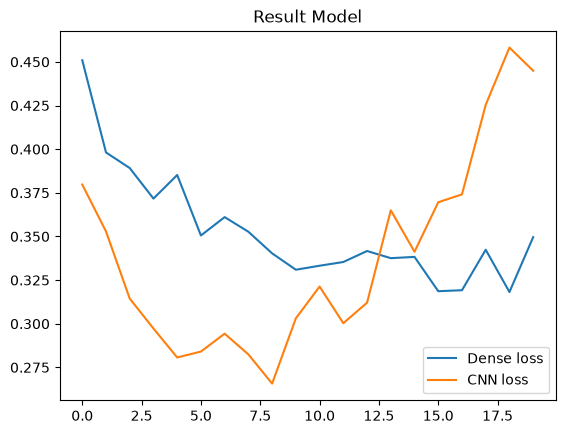

In [38]:
plt.plot(hist_dense_model.history["val_loss"], label="Dense loss")
plt.plot(hist_cnn_model.history["val_loss"], label="CNN loss")
plt.title("Result Model")
plt.legend()
plt.show()

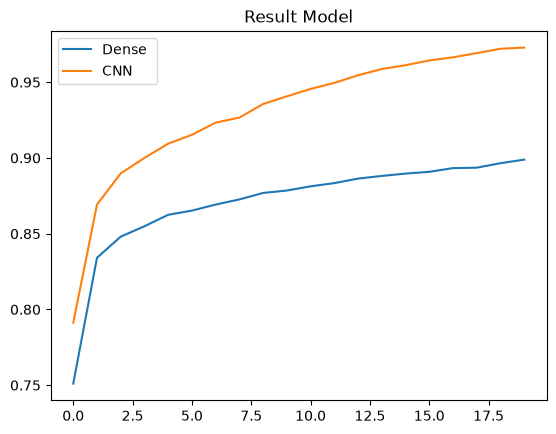

In [39]:
plt.plot(hist_dense_model.history["accuracy"], label="Dense ")
plt.plot(hist_cnn_model.history["accuracy"], label="CNN ")
plt.title("Result Model")
plt.legend()
plt.show()

In [42]:
cnn_model_2 = keras.Sequential([
    keras.Input(shape=(28, 28, 1)),
    layers.Conv2D(64, 5, activation="relu"),
    layers.MaxPooling2D(),
    layers.Conv2D(64, 5, activation="relu"), 
    layers.Conv2D(64, 5, activation="relu"),
    layers.Flatten(),
    layers.Dense(10, activation="softmax")
])

cnn_model_2.compile(optimizer="adam",
                    loss="sparse_categorical_crossentropy",
                    metrics=["accuracy"])

cnn_model_2.summary()

Model: "sequential_7"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_28 (Conv2D)              │ (None, 24, 24, 64)     │         1,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_14 (MaxPooling2D) │ (None, 12, 12, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_29 (Conv2D)              │ (None, 8, 8, 64)       │       102,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_30 (Conv2D)              │ (None, 4, 4, 64)       │       102,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_7 (Flatten)             │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (None, 10)             │        10,250 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 216,842 (847.04 KB)

 Trainable params: 216,842 (847.04 KB)

 Non-trainable params: 0 (0.00 B)

In [44]:
hist_cnn_model_2 = cnn_model_2.fit(x_train, y_train, validation_split=0.2, epochs=20, batch_size=32)

Epoch 1/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 32s 24ms/step - accuracy: 0.8157 - loss: 0.5134 - val_accuracy: 0.8505 - val_loss: 0.4070
Epoch 2/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 35s 28ms/step - accuracy: 0.8802 - loss: 0.3329 - val_accuracy: 0.8850 - val_loss: 0.3220
Epoch 3/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 37s 30ms/step - accuracy: 0.8965 - loss: 0.2811 - val_accuracy: 0.8947 - val_loss: 0.2993
Epoch 4/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 38s 31ms/step - accuracy: 0.9077 - loss: 0.2501 - val_accuracy: 0.9002 - val_loss: 0.2822
Epoch 5/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 34s 27ms/step - accuracy: 0.9175 - loss: 0.2225 - val_accuracy: 0.9075 - val_loss: 0.2674
Epoch 6/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 33s 27ms/step - accuracy: 0.9268 - loss: 0.2010 - val_accuracy: 0.9044 - val_loss: 0.2644
Epoch 7/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 39s 32ms/step - accuracy: 0.9344 - loss: 0.1774 - val_accuracy: 0.9071 - val_loss: 0.2814
Epoch 8/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 34s 27ms/step - accuracy: 0.9387 -

In [56]:
cnn_model_3 = keras.Sequential([
    keras.Input(shape=(28, 28, 1)),
    layers.Conv2D(16, 3, activation="relu"),
    layers.Conv2D(32, 3, activation="relu"), 
    layers.MaxPooling2D(),
    layers.Conv2D(64, 3, activation="relu"),
    layers.MaxPooling2D(),
    layers.Conv2D(64, 3, activation="relu"),
    layers.Flatten(),
    layers.Dense(64, activation="relu"),
    layers.Dropout(0.1),
    layers.Dense(32, activation="relu"),
    layers.Dense(32, activation="relu"),
    layers.Dense(10, activation="softmax")
])

cnn_model_3.compile(optimizer="adam",
                    loss="sparse_categorical_crossentropy",
                    metrics=["accuracy"])

cnn_model_3.summary()

Model: "sequential_18"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_68 (Conv2D)              │ (None, 26, 26, 16)     │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_69 (Conv2D)              │ (None, 24, 24, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_26 (MaxPooling2D) │ (None, 12, 12, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_70 (Conv2D)              │ (None, 10, 10, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_27 (MaxPooling2D) │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_71 (Conv2D)              │ (None, 3, 3, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_18 (Flatten)            │ (None, 576)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_53 (Dense)                │ (None, 64)             │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_14 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_54 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_55 (Dense)                │ (None, 32)             │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_56 (Dense)                │ (None, 10)             │           330 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 100,618 (393.04 KB)

 Trainable params: 100,618 (393.04 KB)

 Non-trainable params: 0 (0.00 B)

In [57]:
hist_cnn_model_3 = cnn_model_3.fit(x_train, y_train, validation_split=0.2, epochs=20, batch_size=32)

Epoch 1/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 19s 13ms/step - accuracy: 0.7610 - loss: 0.6476 - val_accuracy: 0.8443 - val_loss: 0.4161
Epoch 2/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 21s 16ms/step - accuracy: 0.8622 - loss: 0.3845 - val_accuracy: 0.8781 - val_loss: 0.3405
Epoch 3/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 25s 20ms/step - accuracy: 0.8840 - loss: 0.3192 - val_accuracy: 0.8814 - val_loss: 0.3324
Epoch 4/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 22s 17ms/step - accuracy: 0.8984 - loss: 0.2805 - val_accuracy: 0.8949 - val_loss: 0.2941
Epoch 5/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 21s 17ms/step - accuracy: 0.9053 - loss: 0.2577 - val_accuracy: 0.9012 - val_loss: 0.2746
Epoch 6/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 21s 17ms/step - accuracy: 0.9141 - loss: 0.2342 - val_accuracy: 0.9056 - val_loss: 0.2653
Epoch 7/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 22s 17ms/step - accuracy: 0.9205 - loss: 0.2175 - val_accuracy: 0.9121 - val_loss: 0.2493
Epoch 8/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 22s 18ms/step - accuracy: 0.9275 -

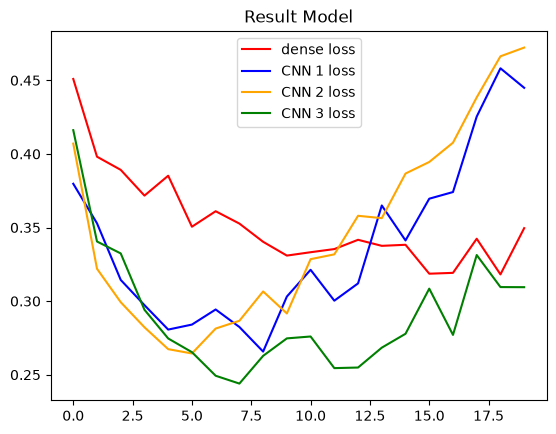

In [58]:
plt.plot(hist_dense_model.history["val_loss"], label="dense loss", color= "red")
plt.plot(hist_cnn_model.history["val_loss"], label="CNN 1 loss", color="blue")
plt.plot(hist_cnn_model_2.history["val_loss"], label="CNN 2 loss", color= "orange")
plt.plot(hist_cnn_model_3.history["val_loss"], label="CNN 3 loss", color="green")
plt.title("Result Model")
plt.legend()
plt.show()